### Importações

In [59]:
# Padrão
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# dataset
import kagglehub
import shutil
import os

# Arsenal de modelos para o benchmark: tentei puxar diferentes naturezas 
from sklearn.linear_model import LogisticRegression # O mais simples e interpretável
from sklearn.neighbors import KNeighborsClassifier # O não-paramétrico da turma
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier # Os ensembles
from sklearn.naive_bayes import GaussianNB # O mais elegante (estatisticamente)
from sklearn.neural_network import MLPClassifier # A rede neural
from sklearn.preprocessing import StandardScaler

### Carregamento

In [60]:
# Importando o dataset e copiando do ambiente global kaggle para o ambiente do projeto (../data)
path = kagglehub.dataset_download("blastchar/telco-customer-churn")
destino = "../data"
shutil.copytree(path, destino, dirs_exist_ok=True)

'../data'

In [61]:
df = pd.read_csv('../data/WA_Fn-UseC_-Telco-Customer-Churn.csv')
df.sample(10)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
6746,8976-OQHGT,Female,0,Yes,Yes,4,Yes,No,DSL,No,...,No,Yes,No,No,Month-to-month,No,Mailed check,56.50,235.1,Yes
1605,7941-RCJOW,Male,0,No,No,65,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,Yes,Credit card (automatic),19.55,1218.65,No
3058,2858-MOFSQ,Female,0,No,Yes,17,Yes,Yes,DSL,No,...,Yes,No,No,No,One year,Yes,Mailed check,55.85,937.5,Yes
3508,2368-GAKKQ,Female,0,No,No,70,Yes,Yes,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),113.65,7939.25,No
6945,6797-LNAQX,Male,0,Yes,Yes,70,Yes,Yes,Fiber optic,No,...,No,No,Yes,Yes,Two year,No,Bank transfer (automatic),98.30,6859.5,Yes
2963,4707-YNOQA,Female,0,Yes,Yes,34,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Credit card (automatic),25.60,917.15,No
2928,1930-QPBVZ,Male,0,Yes,Yes,68,Yes,No,Fiber optic,Yes,...,No,Yes,No,Yes,Two year,No,Bank transfer (automatic),95.10,6683.4,No
1822,4911-BANWH,Female,0,No,Yes,31,Yes,Yes,Fiber optic,No,...,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),86.55,2697.4,Yes
52,6575-SUVOI,Female,1,Yes,No,25,Yes,Yes,DSL,Yes,...,No,Yes,Yes,No,Month-to-month,Yes,Credit card (automatic),69.50,1752.65,No
6891,7853-OETYL,Female,0,Yes,No,4,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.05,129.6,No


In [62]:
display(df.nunique().sort_values(ascending=False).rename('Valores únicos', axis=0)) # para saber a abrangência de dados únicos de cada variável
display(df.nunique().value_counts().sort_index(ascending=False)) # para resumir quantas variáveis do dataset possuem 

customerID          7043
TotalCharges        6531
MonthlyCharges      1585
tenure                73
PaymentMethod          4
StreamingMovies        3
TechSupport            3
OnlineBackup           3
StreamingTV            3
DeviceProtection       3
MultipleLines          3
InternetService        3
OnlineSecurity         3
Contract               3
Partner                2
SeniorCitizen          2
gender                 2
Dependents             2
PhoneService           2
PaperlessBilling       2
Churn                  2
Name: Valores únicos, dtype: int64

7043    1
6531    1
1585    1
73      1
4       1
3       9
2       7
Name: count, dtype: int64

In [63]:
# checando consistência
display(df.info(verbose=True, show_counts=True)) # para olhar missing-values

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

None

**Veredito**: Temos 7 variáveis binárias, 9 variáveis com 3 classes e uma com 4 classes. O dataset **aparentemente** limpo em relação a valores nulos. Sobre a tipagem, o estado atual parece ser coerente com os valores semânticos informados nos metadados, salvo a exceção do vetor `TotalCharges`, que é numérico e consta como `str`. Isso está disponível neste [link](https://www.kaggle.com/datasets/blastchar/telco-customer-churn/data), dentro do *Data Card* na sessão *detail*

In [64]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], 'coerce') # transformando em numérico e testando se alguém ficou vazio
df.isnull().sum().sort_values(ascending=False)

TotalCharges        11
gender               0
SeniorCitizen        0
Partner              0
customerID           0
Dependents           0
tenure               0
MultipleLines        0
PhoneService         0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
InternetService      0
TechSupport          0
StreamingTV          0
Contract             0
StreamingMovies      0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
Churn                0
dtype: int64

Quem são esses casos?

In [65]:
display(df[df['TotalCharges'].isnull()])
display(df[df['tenure'] == 0]['customerID']) #são exatamente as mesmas pessoas

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


488     4472-LVYGI
753     3115-CZMZD
936     5709-LVOEQ
1082    4367-NUYAO
1340    1371-DWPAZ
3331    7644-OMVMY
3826    3213-VVOLG
4380    2520-SGTTA
5218    2923-ARZLG
6670    4075-WKNIU
6754    2775-SEFEE
Name: customerID, dtype: str

Nenhum foi caso de churn e todos tem o "tempo de casa" `tenure` em zero... Podemos assumir que são clientes novos, por isso o TotalCharges não está preenchido. Como conferimos que não há outras pessoas com o `tenure` em zero e são apenas 11 registros de +7K, podemos retirar esses casos pra fora:

In [66]:
df = df.dropna()
df.drop(['customerID'], axis=1)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.50,No
7039,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.90,No
7040,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.60,Yes


In [67]:
colunas_num = ['tenure', 'MonthlyCharges', 'TotalCharges']
df[colunas_num].describe() # SeniorCitizen já veio como binário, então tirei ela fora do hall das variáveis numéricas

,tenure,MonthlyCharges,TotalCharges
count,7032.000000,7032.000000,7032.000000
mean,32.421786,64.798208,2283.300441
std,24.545260,30.085974,2266.771362
min,1.000000,18.250000,18.800000
25%,9.000000,35.587500,401.450000
50%,29.000000,70.350000,1397.475000
75%,55.000000,89.862500,3794.737500
max,72.000000,118.750000,8684.800000


In [68]:
database = df.copy()
database = (
    database.assign(
        gender = lambda x : x['gender'].map({'Male':1, 'Female':0}),
        Partner = lambda x : x['Partner'].map({'Yes':1, 'No':0}),
        Dependents = lambda x : x['Dependents'].map({'Yes':1, 'No':0}),
        PhoneService = lambda x : x['PhoneService'].map({'Yes':1, 'No':0}),
        PaperlessBilling = lambda x : x['PaperlessBilling'].map({'Yes':1, 'No':0}),
        Churn = lambda x : x['Churn'].map({'Yes':1, 'No':0})
    )
)

Com os dados limpos, podemos começar a vislumbrar as relações entre as variáveis a partir de um breve (pois não é o intuito aqui) trecho de exploração visual. Não vamos fazer um desfile carnavalesco de gráficos aqui, mas procurar a objetividade na tentativa de responder a seguinte questão: **quais características separam os clientes que cancelam dos que ficam?**. O ponta-pé inicial é olhar para o próprio alvo e entender seu balanço (que vai nutrir decisões futuras de modelagem).

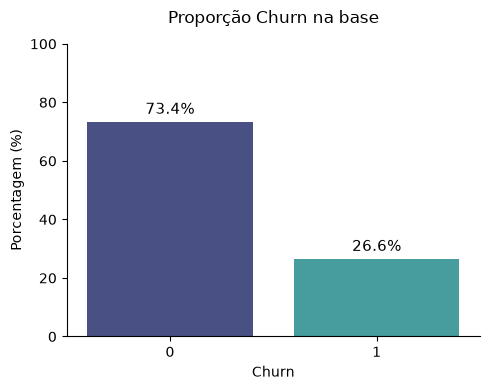

In [69]:
# %%
fig, ax = plt.subplots(figsize=(5, 4))
proporcoes = database['Churn'].value_counts(normalize=True) * 100

sns.barplot(x=proporcoes.index, y=proporcoes.values, palette = 'mako', ax=ax, legend=False, hue=proporcoes.index)
ax.set_title('Proporção Churn na base', pad=15)
ax.set_ylabel('Porcentagem (%)')
ax.set_xlabel('Churn')
ax.set_ylim(0, 100)

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3, fontsize=11)

sns.despine()
plt.tight_layout()
plt.show()

O desbalanceamento das classes torna o threshold padrão de 0.5 ineficiente. Como as probabilidades tendem a ser baixas, manter esse limiar gera uma falsa acurácia sustentada por uma sensibilidade pífia: o modelo classifica quase toda a base como 'não-churn', deixando a imensa maioria dos verdadeiros cancelamentos passar despercebida. Heuristicamente, a pergunta central da modelagem é: o que custa mais? Em telecomunicações, assim como na saúde, o Erro Tipo II (Falso-Negativo) é o mais grave. Perder a receita vitalícia (do LTV) de um cliente que cancela em silêncio custa infinitamente mais para o negócio do que o custo operacional de oferecer uma promoção de retenção a um Falso-Positivo. E na saúde, nem preciso dizer o quão perigiso é afirmar que um paciente doente está saudável...

Olhemos agora as categóricas não-binárias do dataset (de forma univariada). Vamos ver quais são mais relevantes levando em conta que se as classes delas têm proporções semelhantes entre si. 

- Se calcularmos, para cada uma delas a média aritmética de cada cla, encontraremos a proporção de 1's e 0's para cada uma;
* A diferença entre essas proporções provê uma intuição univariada de relevância (em termos de variância) dessa variável (sozinha) na classificação do Churn.

In [70]:
relevancia = {}

cat_vars = ['MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 
            'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 
            'Contract', 'PaymentMethod']

for col in cat_vars:
    taxas = database.groupby(col)['Churn'].mean()
    amplitude_risco = taxas.max() - taxas.min() 
    relevancia[col] = amplitude_risco

# Transforma num DataFrame, ordena e encadeia (method chaining)
df_ranking = (
    pd.DataFrame(list(relevancia.items()), columns=['Variável', 'Delta_Risco_Churn'])
    .sort_values(by='Delta_Risco_Churn', ascending=False)
    .reset_index(drop=True)
)

display(df_ranking)

,Variável,Delta_Risco_Churn
0,Contract,0.398610
1,InternetService,0.344586
2,OnlineSecurity,0.343445
3,TechSupport,0.342133
4,OnlineBackup,0.325075
5,DeviceProtection,0.317061
6,PaymentMethod,0.300323
7,StreamingMovies,0.262947
8,StreamingTV,0.261009
9,MultipleLines,0.036485


A variável Contract mostra-se a mais importante, apresentando uma amplitude de quase 40 pontos percentuais na taxa de risco entre suas classes. Ela é seguida em importância por InternetService, OnlineSecurity e TechSupport, todas apresentando um delta de risco em torno de 34%.

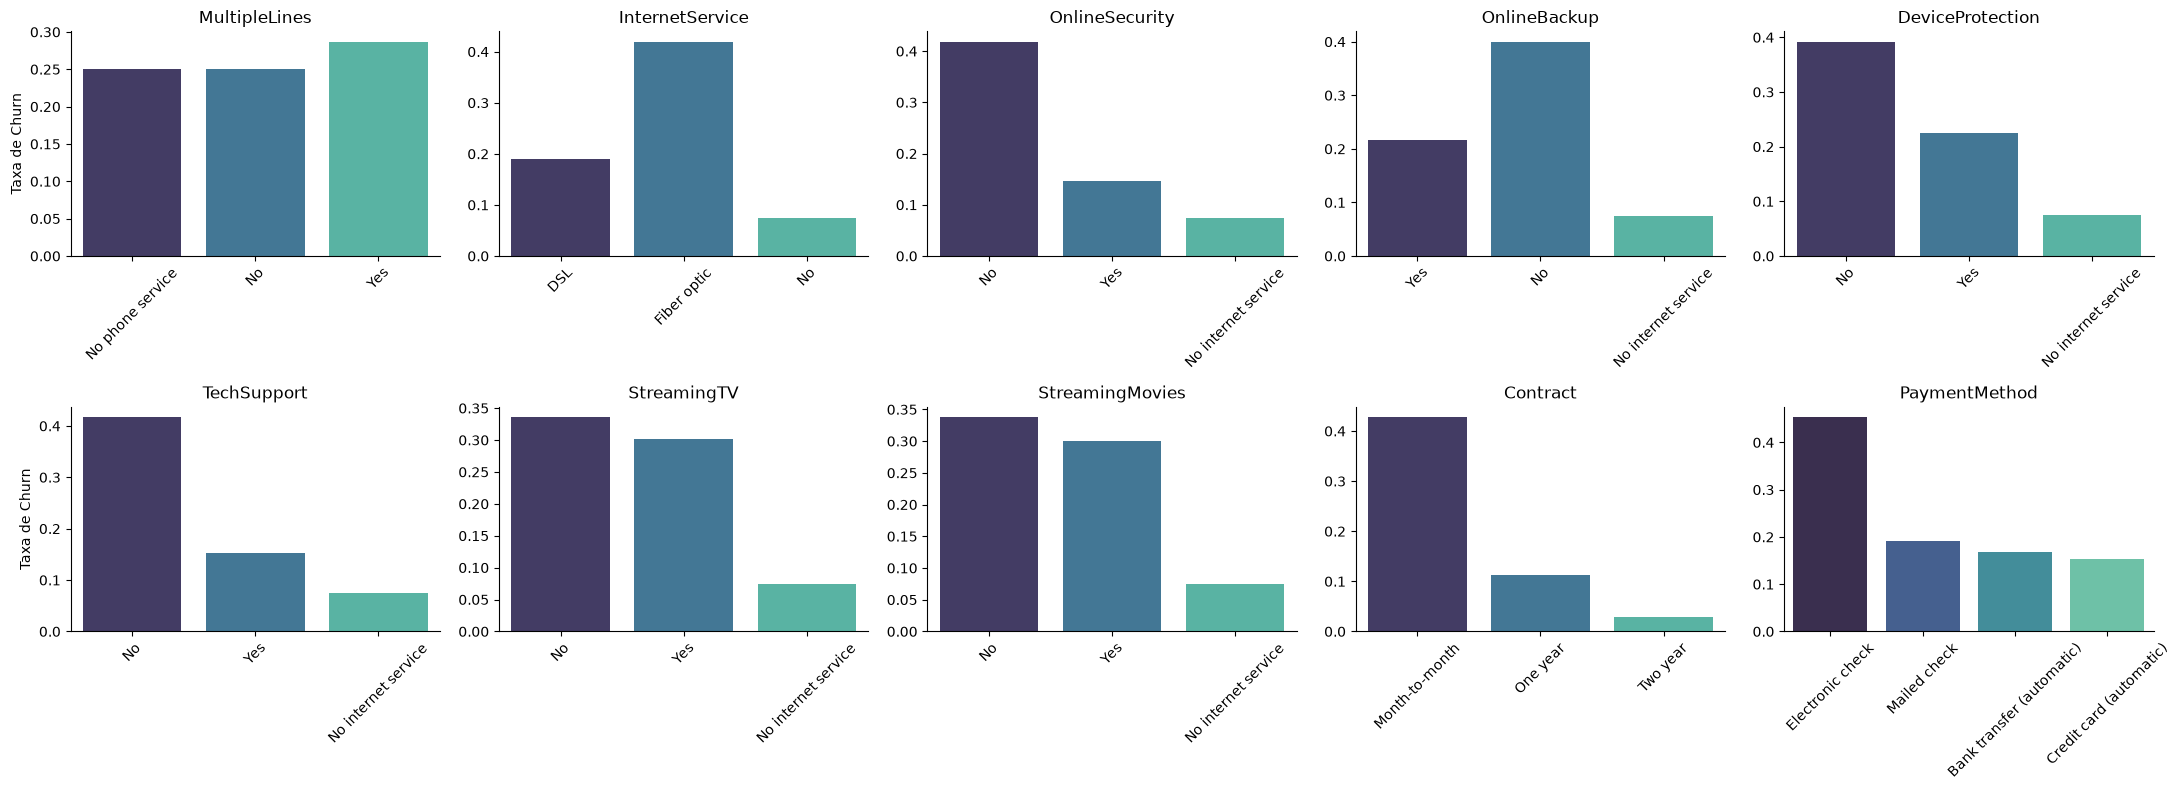

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(22, 8))
axes = axes.flatten() # Transforma a matriz 2x5 num array 1D para iterar facilmente

for i, col in enumerate(cat_vars):
    sns.barplot(data=database, x=col, y='Churn', ax=axes[i], palette='mako', errorbar=None, hue=col)
    axes[i].set_title(col, fontsize=12)
    axes[i].set_ylabel('Taxa de Churn' if i % 5 == 0 else '') # Y label só na 1ª coluna
    axes[i].set_xlabel('')
    axes[i].tick_params(axis='x', rotation=45) # Inclina os rótulos das classes pra não ficar zoado

sns.despine()
plt.tight_layout()
plt.show()

A análise individual das variáveis categóricas do dataset não é suficiente em termos de *feature-selection*, mas nos mostra que existem fortes indícios de que clientes com o seguinte perfil são riscos de Churn: clientes marcados com 'No' nas variáveis ``OnlineSecurity``, ``OnlineBackup``, ``DeviceProtection`` e ``TechSupport`` possuem taxas de churn drasticamente superiores àqueles que contratam esses serviços. Em suma, os serviços agregados de internet são impulsionadores do LTV aqui nesse contexto.

A variável ``MultipleLines`` demonstrou ter baixo poder discriminatório com um delta nas proporções da variável predita de só 3,6%. Mas esse cenário que temos não leva em consideração o poder da interação entre as variáveis. Essa última por exemplo, não tem valor sozinha, mas pode ser que tenha algum poder discriminatório interessante em algum grau de profundidade de um RandomForest, por exemplo. Há uma miríade de possibilidades que exploraremos mais à frente.


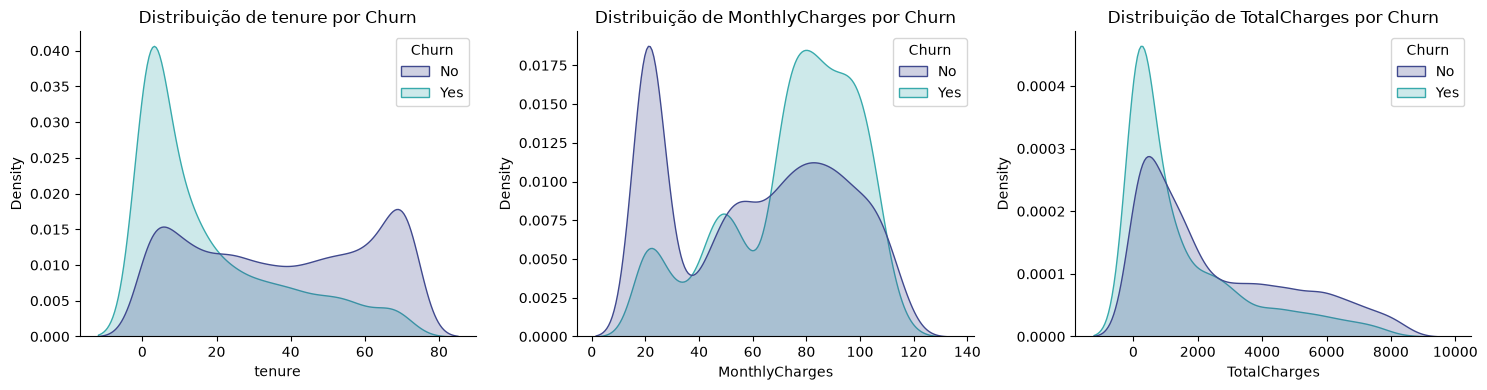

In [73]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4)) # 3 gráficos num quadro só
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

for ax, col in zip(axes, num_cols):
    sns.kdeplot(data=df, x=col, hue='Churn', fill=True, common_norm=False, ax=ax, palette='mako')
    ax.set_title(f'Distribuição de {col} por Churn')

sns.despine()
plt.tight_layout()
plt.show()

O churn ocorre massivamente no início do relacionamento, representado pelo pico em baixo `tenure`, e afeta de forma desproporcional os clientes com mensalidades mais caras no ``MonthlyCharges``. Olhando a distribuição do `TotalChargres`, vemos que ambas as classes possuem um pico agudo muito próximo ao zero e uma cauda longa. O que isso nos diz é que ``TotalCharges`` é uma variável colinear, funcionando basicamente como um subproduto determinístico da multiplicação entre tenure e ``MonthlyCharges`` (e a definição nos metadados indica a mesma coisa). 


Tendo em mente que temos variáveis de diferentes naturezas que podem se relacionar a diferentes magnitudes com a nossa variável alvo, podemos dar o ponto de partida na análise da matriz **$X$** a partir de um heatmap que dá uma intuição da relação linear entre os preditores numéricos e o nosso $Y$

In [74]:
database.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,0,0,1,0,1,0,No phone service,DSL,No,...,No,No,No,No,Month-to-month,1,Electronic check,29.85,29.85,0
1,5575-GNVDE,1,0,0,0,34,1,No,DSL,Yes,...,Yes,No,No,No,One year,0,Mailed check,56.95,1889.50,0
2,3668-QPYBK,1,0,0,0,2,1,No,DSL,Yes,...,No,No,No,No,Month-to-month,1,Mailed check,53.85,108.15,1
3,7795-CFOCW,1,0,0,0,45,0,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,0,Bank transfer (automatic),42.30,1840.75,0
4,9237-HQITU,0,0,0,0,2,1,No,Fiber optic,No,...,No,No,No,No,Month-to-month,1,Electronic check,70.70,151.65,1


In [75]:
df.nunique()

customerID          7032
gender                 2
SeniorCitizen          2
Partner                2
Dependents             2
tenure                72
PhoneService           2
MultipleLines          3
InternetService        3
OnlineSecurity         3
OnlineBackup           3
DeviceProtection       3
TechSupport            3
StreamingTV            3
StreamingMovies        3
Contract               3
PaperlessBilling       2
PaymentMethod          4
MonthlyCharges      1584
TotalCharges        6530
Churn                  2
dtype: int64